<a href="https://colab.research.google.com/github/Mehedi-Hasan-Robel/ML-project/blob/ml-project/Customer_Churn_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('/content/customer_churn_dataset-testing-master.csv')
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


In [3]:
df.shape

(64374, 12)

In [4]:
df.columns

Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency',
       'Support Calls', 'Payment Delay', 'Subscription Type',
       'Contract Length', 'Total Spend', 'Last Interaction', 'Churn'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   CustomerID         64374 non-null  int64 
 1   Age                64374 non-null  int64 
 2   Gender             64374 non-null  object
 3   Tenure             64374 non-null  int64 
 4   Usage Frequency    64374 non-null  int64 
 5   Support Calls      64374 non-null  int64 
 6   Payment Delay      64374 non-null  int64 
 7   Subscription Type  64374 non-null  object
 8   Contract Length    64374 non-null  object
 9   Total Spend        64374 non-null  int64 
 10  Last Interaction   64374 non-null  int64 
 11  Churn              64374 non-null  int64 
dtypes: int64(9), object(3)
memory usage: 5.9+ MB


In [6]:
df.isnull().sum()

,0
CustomerID,0
Age,0
Gender,0
Tenure,0
Usage Frequency,0
Support Calls,0
Payment Delay,0
Subscription Type,0
Contract Length,0
Total Spend,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000
mean,32187.500000,41.970982,31.994827,15.080234,5.400690,17.133952,541.023379,15.498850,0.473685
std,18583.317451,13.924911,17.098234,8.816470,3.114005,8.852211,260.874809,8.638436,0.499311
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,16094.250000,30.000000,18.000000,7.000000,3.000000,10.000000,313.000000,8.000000,0.000000
50%,32187.500000,42.000000,33.000000,15.000000,6.000000,19.000000,534.000000,15.000000,0.000000
75%,48280.750000,54.000000,47.000000,23.000000,8.000000,25.000000,768.000000,23.000000,1.000000
max,64374.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [9]:
df.describe(include = 'object')

,Gender,Subscription Type,Contract Length
count,64374,64374,64374
unique,2,3,3
top,Female,Standard,Monthly
freq,34353,21502,22130


In [10]:
df.Gender.unique()

array(['Female', 'Male'], dtype=object)

In [11]:
df.Gender.value_counts()

,count
Gender,
Female,34353
Male,30021


In [12]:
df.Gender.value_counts(normalize = True)*100

,proportion
Gender,
Female,53.364712
Male,46.635288


In [13]:
df['Subscription Type'].unique()

array(['Basic', 'Standard', 'Premium'], dtype=object)

In [14]:
df['Subscription Type'].value_counts()

,count
Subscription Type,
Standard,21502
Basic,21451
Premium,21421


In [15]:
df['Subscription Type'].value_counts(normalize = True)

,proportion
Subscription Type,
Standard,0.334017
Basic,0.333225
Premium,0.332759


In [16]:
df['Contract Length'].unique()

array(['Monthly', 'Annual', 'Quarterly'], dtype=object)

In [17]:
df['Contract Length'].value_counts()

,count
Contract Length,
Monthly,22130
Annual,21410
Quarterly,20834


In [18]:
df['Contract Length'].value_counts(normalize = True)*100

,proportion
Contract Length,
Monthly,34.377233
Annual,33.258769
Quarterly,32.363998


In [19]:
df = df.drop('CustomerID',axis = 1)

In [20]:
df.head()

,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,53,Female,58,24,9,2,Standard,Annual,533,18,0


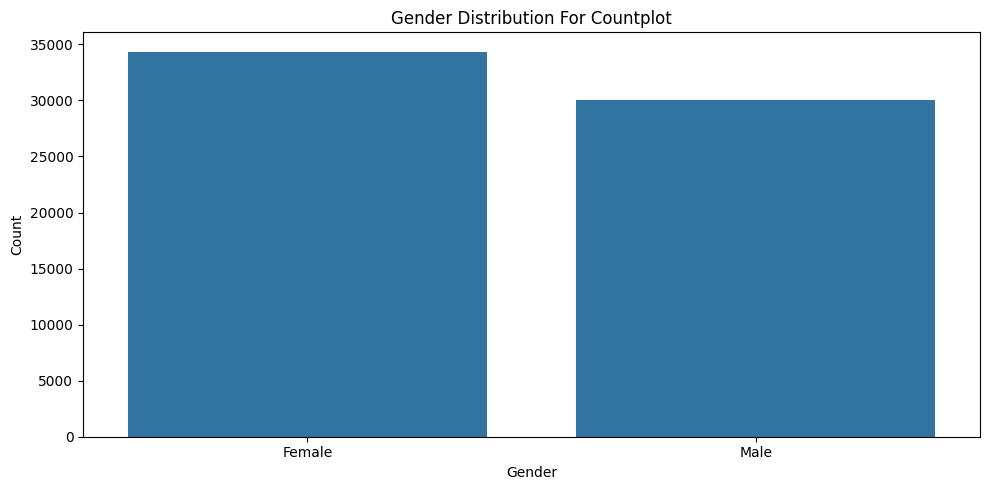

In [21]:
plt.figure(figsize = (10,5))
sns.countplot(x = 'Gender',data = df)
plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Gender Distribution For Countplot')
plt.tight_layout()
plt.show()

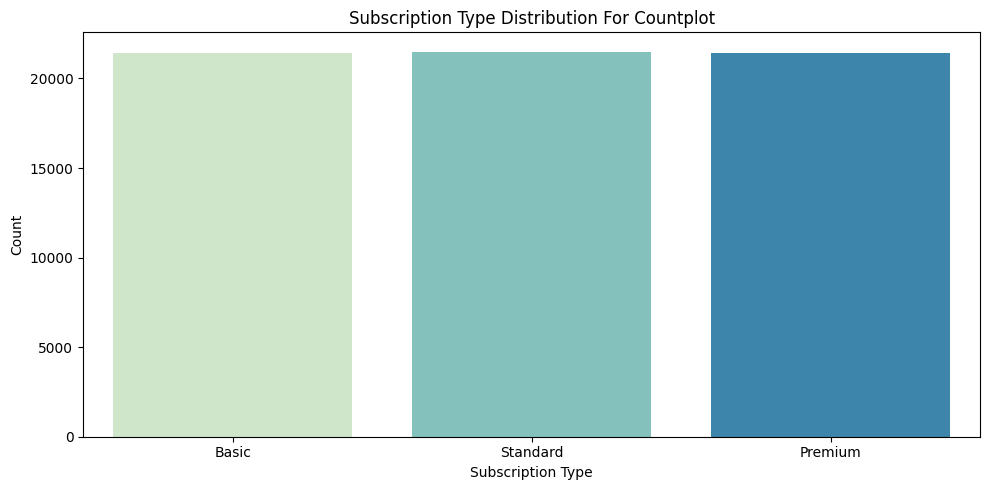

In [22]:
plt.figure(figsize = (10,5))
sns.countplot(x = 'Subscription Type',data = df,palette='GnBu')
plt.xlabel('Subscription Type')
plt.ylabel('Count')
plt.title('Subscription Type Distribution For Countplot')
plt.tight_layout()
plt.show()

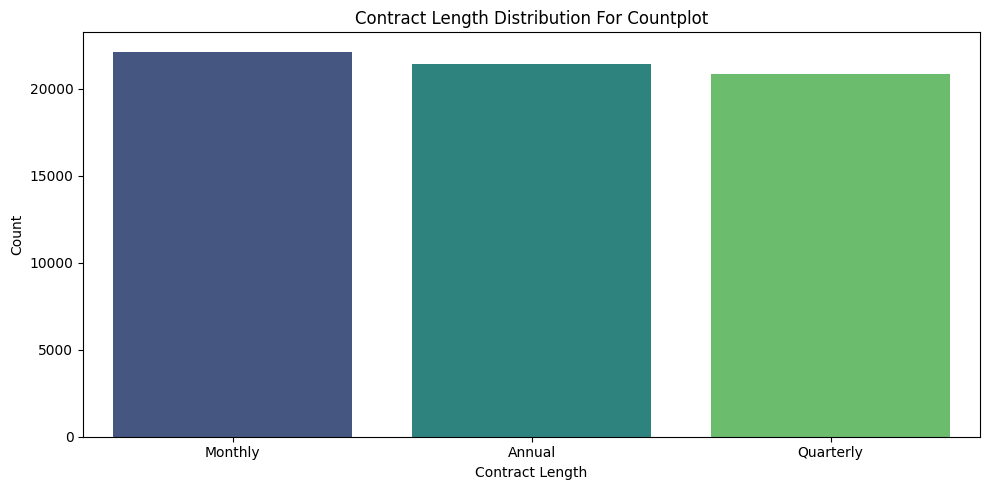

In [23]:
plt.figure(figsize = (10,5))
sns.countplot(x = 'Contract Length',data = df,palette='viridis')
plt.xlabel('Contract Length')
plt.ylabel('Count')
plt.title('Contract Length Distribution For Countplot')
plt.tight_layout()
plt.show()

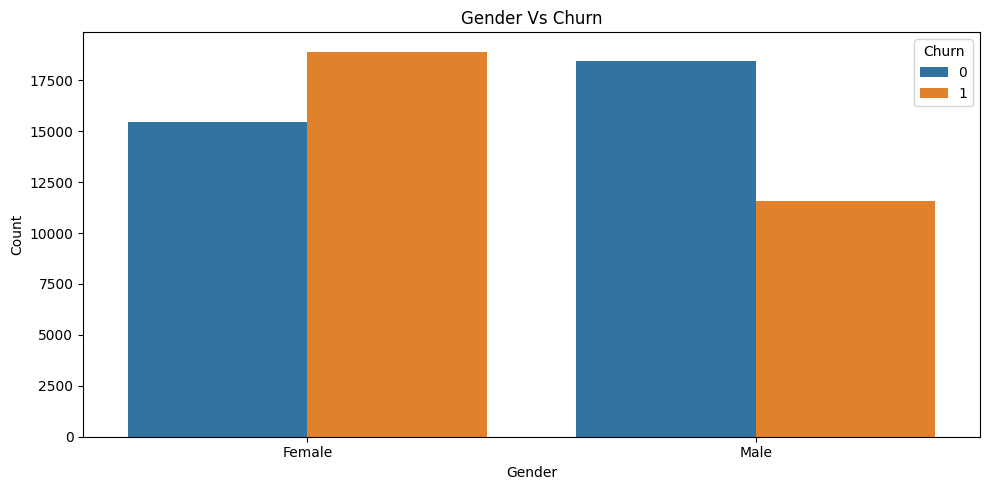

In [24]:
plt.figure(figsize = (10,5))
sns.countplot(x = 'Gender',data = df,hue = 'Churn')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Gender Vs Churn')
plt.tight_layout()
plt.show()

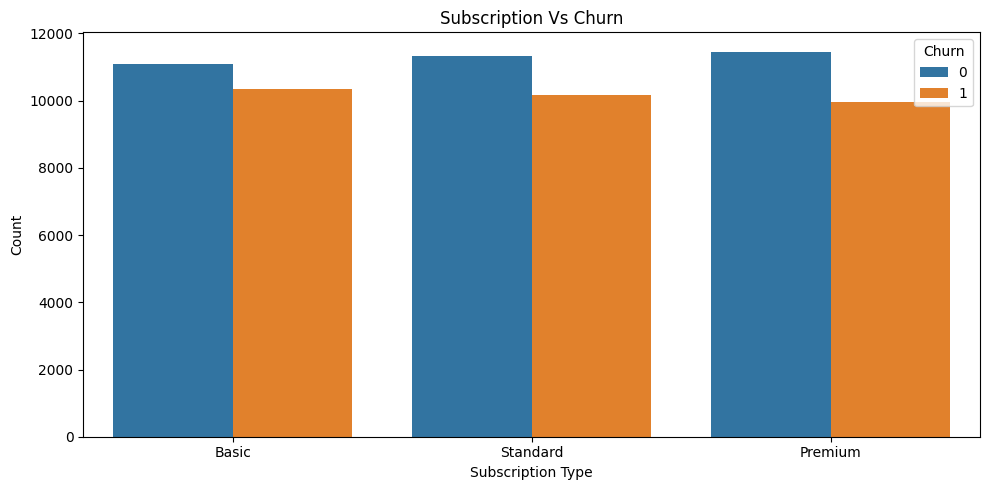

In [25]:
plt.figure(figsize = (10,5))
sns.countplot(x = 'Subscription Type',data = df,hue='Churn')
plt.xlabel('Subscription Type')
plt.ylabel('Count')
plt.title('Subscription Vs Churn')
plt.tight_layout()
plt.show()

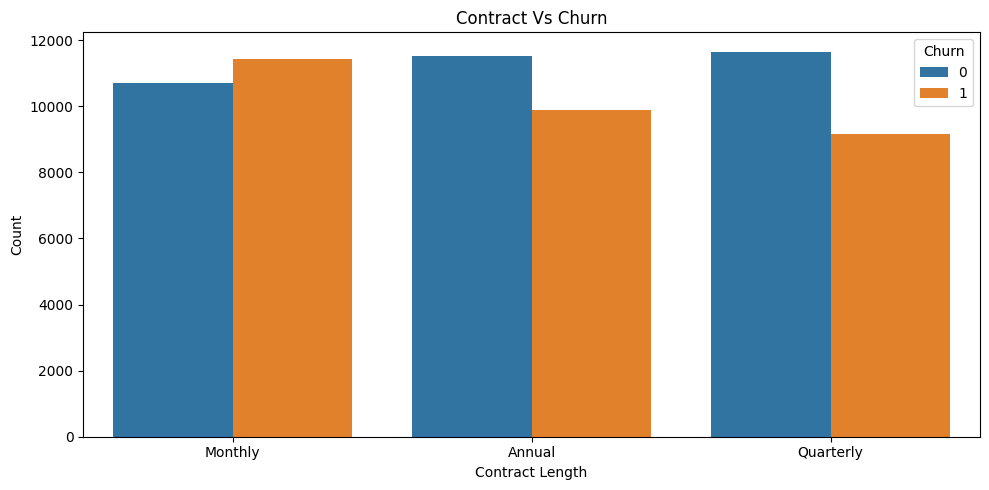

In [26]:
plt.figure(figsize = (10,5))
sns.countplot(x = 'Contract Length',data = df,hue='Churn')
plt.xlabel('Contract Length')
plt.ylabel('Count')
plt.title('Contract Vs Churn')
plt.tight_layout()
plt.show()

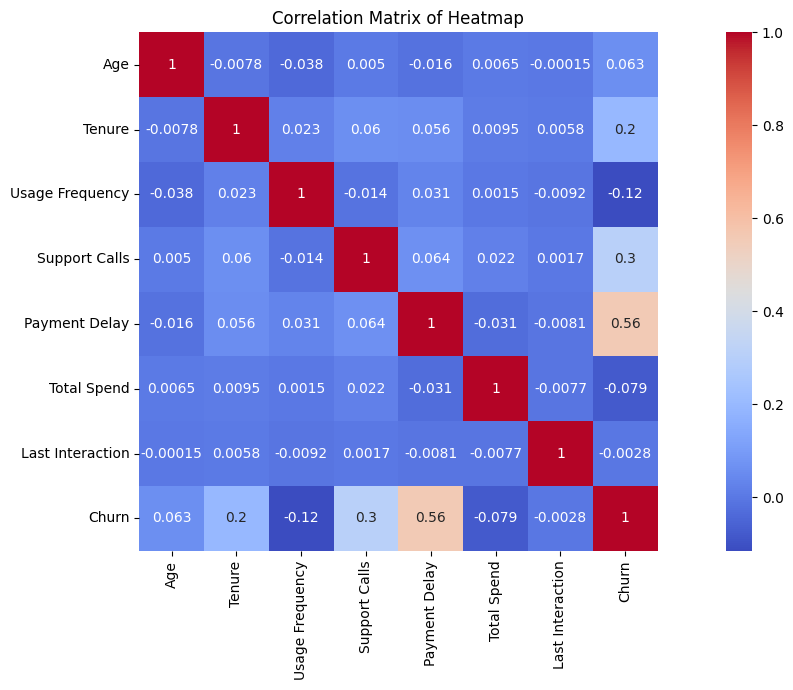

In [27]:
corr_matrix = df.corr(numeric_only=True)
plt.figure(figsize = (14,7))
sns.heatmap(corr_matrix,annot = True,cmap = 'coolwarm',square = True)
plt.title('Correlation Matrix of Heatmap')
plt.tight_layout()
plt.show()

In [28]:
cat_cols = df.select_dtypes(include = 'object').columns.tolist()
cat_cols

['Gender', 'Subscription Type', 'Contract Length']

In [29]:
df = pd.get_dummies(df,columns = cat_cols,drop_first = True).astype(int)
df.head()

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn,Gender_Male,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Monthly,Contract Length_Quarterly
0,22,25,14,4,27,598,9,1,0,0,0,1,0
1,41,28,28,7,13,584,20,0,0,0,1,1,0
2,47,27,10,2,29,757,21,0,1,1,0,0,0
3,35,9,12,5,17,232,18,0,1,1,0,0,1
4,53,58,24,9,2,533,18,0,0,0,1,0,0


In [30]:
x = df.drop('Churn',axis = 1)
y = df['Churn']

In [31]:
x.shape

(64374, 12)

In [32]:
y.shape

(64374,)

In [33]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,shuffle = True,random_state = 42)

In [34]:
x_train.shape

(51499, 12)

In [35]:
y_train.shape

(51499,)

In [36]:
x_test.shape

(12875, 12)

In [37]:
y_test.shape

(12875,)

In [38]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaler = scaler.fit_transform(x_train)
x_test_scaler = scaler.transform(x_test)

In [39]:
x_train_scaler

array([[ 1.00748863,  0.58691645, -0.46172589, ..., -0.70755994,
        -0.726372  ,  1.4557682 ],
       [ 0.86400944,  1.63912853, -1.14230525, ...,  1.41330783,
        -0.726372  ,  1.4557682 ],
       [-0.78600122, -1.16677034, -1.48259492, ..., -0.70755994,
        -0.726372  , -0.68692255],
       ...,
       [-0.64252203,  0.87919758, -0.68858568, ...,  1.41330783,
        -0.726372  ,  1.4557682 ],
       [-1.28817837,  1.46375985,  0.44571325, ..., -0.70755994,
        -0.726372  , -0.68692255],
       [-0.64252203,  0.11926664,  0.44571325, ...,  1.41330783,
        -0.726372  ,  1.4557682 ]], shape=(51499, 12))

In [40]:
x_test_scaler

array([[ 0.93574903, -0.69912053,  1.01286271, ...,  1.41330783,
         1.37670505, -0.68692255],
       [-1.00122   , -0.28992695,  1.69344206, ..., -0.70755994,
        -0.726372  ,  1.4557682 ],
       [ 1.65314497,  1.63912853,  0.21885346, ..., -0.70755994,
        -0.726372  ,  1.4557682 ],
       ...,
       [ 0.72053025,  1.05456626, -0.91544546, ..., -0.70755994,
        -0.726372  ,  1.4557682 ],
       [-1.57513675,  1.40530362,  1.1262926 , ...,  1.41330783,
        -0.726372  , -0.68692255],
       [ 0.2183531 ,  0.93765381,  0.67257303, ..., -0.70755994,
         1.37670505, -0.68692255]], shape=(12875, 12))

In [41]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [42]:
model = Sequential()
model.add(Dense(units=64,activation = 'relu',input_dim = x_train.shape[1]))
model.add(Dropout(0.2))
model.add(Dense(units = 32,activation = 'relu'))
model.add(Dropout(0.2))
model.add(Dense(units = 16,activation = 'relu'))
model.add(Dropout(0.2))
model.add(Dense(units=1,activation = 'sigmoid'))

In [43]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

In [44]:
model.compile(optimizer='adam',loss = 'binary_crossentropy',metrics = ['accuracy'])

In [45]:
early_stop = EarlyStopping(monitor = 'val_loss',patience = 10, restore_best_weights = True)

In [46]:
history = model.fit(x_train_scaler,y_train,epochs = 100,batch_size = 32,validation_split = 0.2, callbacks = [early_stop])

Epoch 1/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8392 - loss: 0.3586 - val_accuracy: 0.9020 - val_loss: 0.2317
Epoch 2/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8922 - loss: 0.2539 - val_accuracy: 0.9291 - val_loss: 0.1719
Epoch 3/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9175 - loss: 0.1990 - val_accuracy: 0.9498 - val_loss: 0.1307
Epoch 4/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9325 - loss: 0.1669 - val_accuracy: 0.9601 - val_loss: 0.1050
Epoch 5/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9462 - loss: 0.1352 - val_accuracy: 0.9709 - val_loss: 0.0773
Epoch 6/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9529 - loss: 0.1193 - val_accuracy: 0.9743 - val_loss: 0.0664
Epoch 7/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9579 - loss: 0.1073 - val_accuracy: 0.9790 - val_loss: 0.0589
Epoch 8/100
1288/1288 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9645 - loss: 

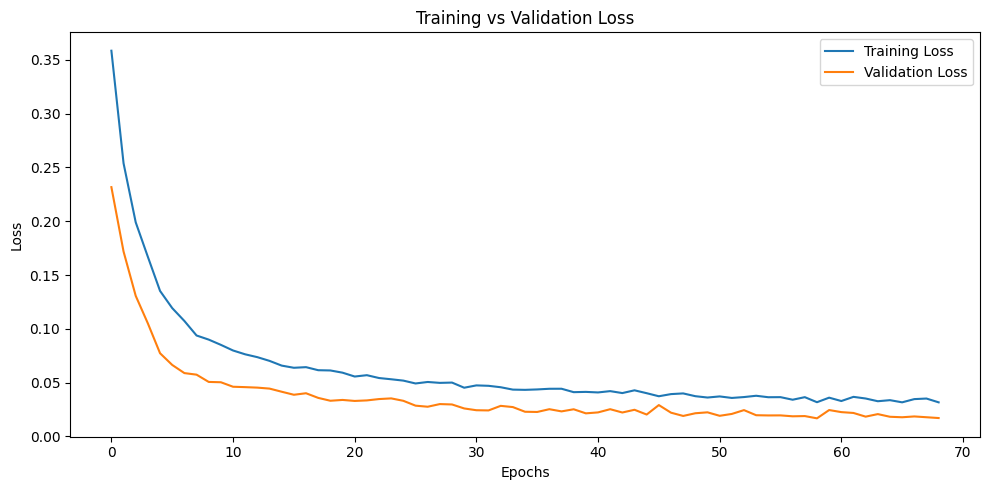

In [47]:
plt.figure(figsize=(10,5))
plt.plot(history.history['loss'],label = 'Training Loss')
plt.plot(history.history['val_loss'],label = 'Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.tight_layout()
plt.legend()
plt.show()


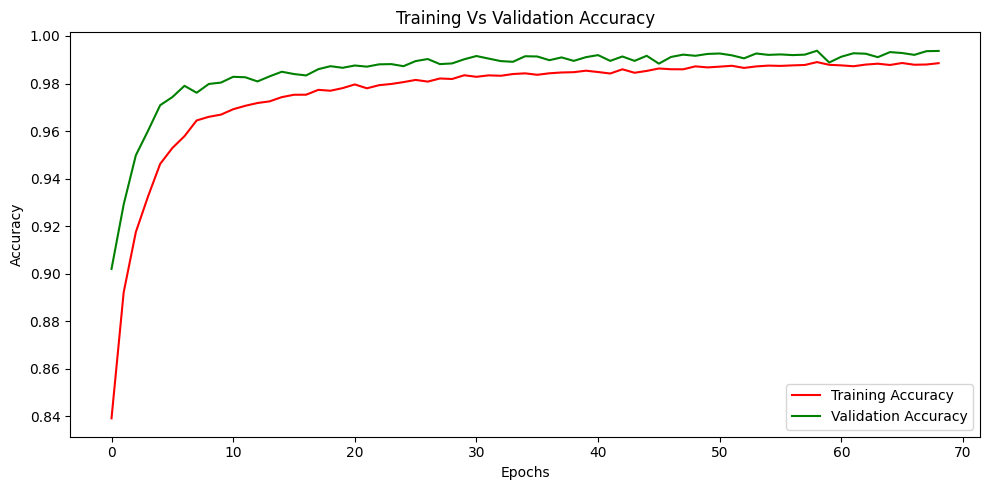

In [48]:
plt.figure(figsize = (10,5))
plt.plot(history.history['accuracy'],label = 'Training Accuracy',color = 'r')
plt.plot(history.history['val_accuracy'],label = 'Validation Accuracy',color = 'g')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training Vs Validation Accuracy')
plt.tight_layout()
plt.legend()
plt.show()

In [49]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix



In [50]:
y_pred = model.predict(x_test_scaler)

403/403 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [51]:

y_pred = (y_pred > 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f'Accuracy:  {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall:    {recall:.4f}')
print(f'F1 Score:  {f1:.4f}')

Accuracy:  0.9936
Precision: 0.9924
Recall:    0.9939
F1 Score:  0.9932


In [52]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      6793
           1       0.99      0.99      0.99      6082

    accuracy                           0.99     12875
   macro avg       0.99      0.99      0.99     12875
weighted avg       0.99      0.99      0.99     12875



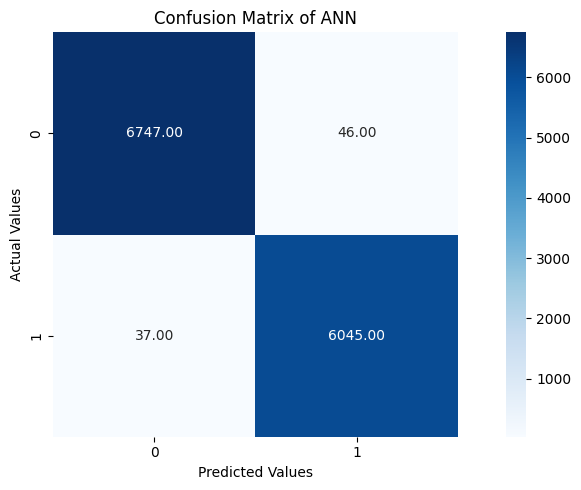

In [53]:
plt.figure(figsize = (10,5))
cm = confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot = True,fmt = '.2f',cmap = 'Blues',square=True)
plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('Confusion Matrix of ANN')
plt.tight_layout()
plt.show()